# 03 — Arbre de décision, Random Forest et XGBoost

**Objectif** : voir si des modèles à base d'arbres font mieux que la régression logistique (ROC AUC 0,747, notebook 02).

Questions traitées :
1. Comment un arbre de décision choisit-il ses questions, et que donne-t-il seul ?
2. Comment la profondeur fait-elle passer du sous-apprentissage au sur-apprentissage ?
3. Que gagnent les méthodes d'ensemble : le **bagging** (Random Forest) et le **boosting** (XGBoost) ?
4. Quelles variables XGBoost utilise-t-il le plus ?

**Règles suivies** : mêmes 5 plis et mêmes 82 variables de base que dans le notebook 02, pour une comparaison équitable.
Le jeu de test n'est toujours pas chargé.

*Durée d'exécution : environ 40 minutes sur 8 cœurs, surtout pour XGBoost.*

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from matplotlib.ticker import MultipleLocator
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

sys.path.insert(0, "..")  # pour importer src/
from src.prepare_data import COLONNES_HORS_MODELE, VARIABLES_NOUVELLES

BLEU, ORANGE = "#2a78d6", "#eb6834"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})

## 1. Données, plis et résultats du notebook 02

In [2]:
DOSSIER_PROCESSED = Path("..") / "data" / "processed"
train = pd.read_parquet(DOSSIER_PROCESSED / "train.parquet")
y = train["TARGET"].to_numpy()

variables = [c for c in train.columns if c not in COLONNES_HORS_MODELE + VARIABLES_NOUVELLES]
categorielles = [c for c in variables if not pd.api.types.is_numeric_dtype(train[c])]
numeriques = [c for c in variables if c not in categorielles]
X = train[variables]
print(f"{len(train):,} prêts, {len(variables)} variables de base ({len(numeriques)} numériques, {len(categorielles)} catégorielles)")

PLIS = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # les mêmes plis que dans le notebook 02
INDICES_PLIS = [validation for _, validation in PLIS.split(X, y)]
resultats = []


def evaluer(nom, score, nb_variables):
    """ROC AUC et PR AUC sur chacun des 5 plis (score : plus il est élevé, plus le risque est grand)."""
    roc = [roc_auc_score(y[i], score[i]) for i in INDICES_PLIS]
    pr = [average_precision_score(y[i], score[i]) for i in INDICES_PLIS]
    resultats.append({"modele": nom, "variables": nb_variables, "roc_auc": np.mean(roc),
                      "ecart_type": np.std(roc), "pr_auc": np.mean(pr), "auc_par_pli": roc})
    print(f"{nom} : ROC AUC {np.mean(roc):.3f} ± {np.std(roc):.3f}, PR AUC {np.mean(pr):.3f}")


def predire_oof(modele):
    """Probabilité de défaut out-of-fold : chaque client est prédit par le modèle qui ne l'a pas vu."""
    return cross_val_predict(modele, X, y, cv=PLIS, method="predict_proba", n_jobs=5)[:, 1]


# Prédictions out-of-fold du notebook 02, sur les mêmes clients dans le même ordre
oof_02 = pd.read_parquet(DOSSIER_PROCESSED / "oof_02.parquet")
assert (oof_02["SK_ID_CURR"].to_numpy() == train["SK_ID_CURR"].to_numpy()).all()
evaluer("Baseline : moyenne des scores externes", oof_02["baseline_scores_externes"].to_numpy(), 3)
evaluer("Régression logistique complète", oof_02["logistique_complete"].to_numpy(), len(variables))

246,008 prêts, 82 variables de base (69 numériques, 13 catégorielles)


Baseline : moyenne des scores externes : ROC AUC 0.716 ± 0.003, PR AUC 0.189


Régression logistique complète : ROC AUC 0.747 ± 0.002, PR AUC 0.227


## 2. Préparer les variables pour des arbres

Un arbre ne pose que des questions du type « `EXT_SOURCE_3` < 0,37 ? ». Il ne regarde que l'**ordre** des valeurs. Par conséquent :
- **pas de standardisation ni de logarithme** : le revenu extrême de 117 millions ne pèse pas plus que n'importe quel gros revenu ;
- **les valeurs manquantes sont gérées par les arbres eux-mêmes** (scikit-learn depuis la version 1.3, XGBoost depuis toujours) :
  à chaque coupure, l'arbre apprend de quel côté envoyer les clients sans valeur ;
- **les variables catégorielles** sont numérotées (`OrdinalEncoder`) : une modalité = un entier, les modalités de moins de 100 prêts
  sont regroupées, une valeur manquante vaut −1. L'ordre des numéros est arbitraire, mais un arbre peut isoler une modalité
  en deux coupures. C'est beaucoup plus compact que les 140 colonnes du one-hot.

In [3]:
def preparation_arbres():
    return ColumnTransformer([
        ("numeriques", "passthrough", numeriques),
        ("categorielles", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                         encoded_missing_value=-1, min_frequency=100), categorielles),
    ], verbose_feature_names_out=False)


# Aperçu seulement : ici l'encodeur est ajusté sur tout l'apprentissage pour l'affichage ;
# dans les modèles, il est réajusté sur les plis d'entraînement (il est dans le pipeline).
apercu = preparation_arbres().fit(X).transform(X.head(3))
pd.DataFrame(apercu, columns=numeriques + categorielles)[["EXT_SOURCE_1", "AMT_CREDIT"] + categorielles[:4]]

,EXT_SOURCE_1,AMT_CREDIT,NAME_CONTRACT_TYPE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE
0,0.384582,227520.0,0.0,6.0,0.0,1.0
1,NaN,161730.0,0.0,6.0,0.0,4.0
2,NaN,728847.0,0.0,5.0,3.0,4.0


## 3. Arbre de décision

### 3.1 Comment un arbre choisit ses questions

À chaque nœud, l'arbre teste toutes les variables et tous les seuils possibles, et garde la coupure qui rend
les deux groupes obtenus les plus **purs**. La pureté se mesure par l'**indice de Gini** :

$$\text{Gini} = 1 - p^2 - (1-p)^2 = 2p(1-p)$$

où $p$ est la part de défauts dans le groupe. Un groupe sans aucun défaut a un Gini de 0. Avec 8,1 % de défauts, le Gini de départ vaut 0,148.
Une fois l'arbre construit, la probabilité de défaut prédite pour un client est **la part de défauts dans sa feuille**.

Un arbre de profondeur 3 (8 feuilles), entraîné sur tout le jeu d'apprentissage, pour lire les règles :

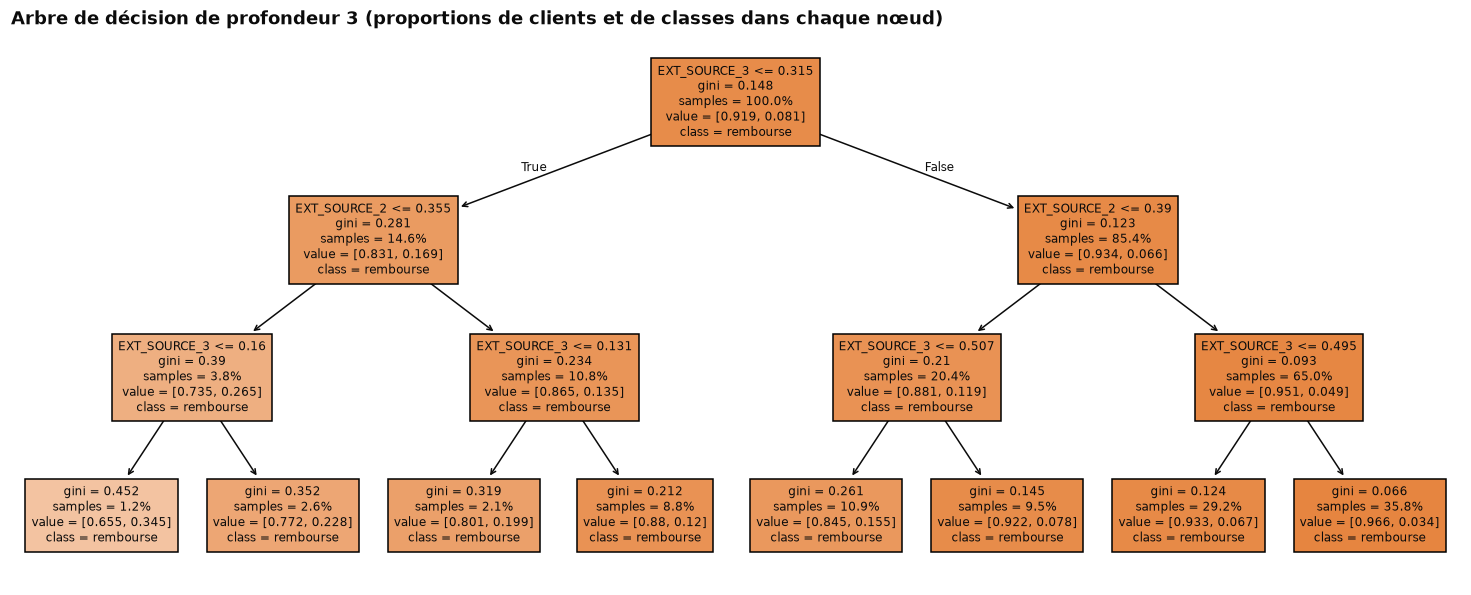

In [4]:
arbre_lisible = make_pipeline(preparation_arbres(), DecisionTreeClassifier(max_depth=3, random_state=42)).fit(X, y)

fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(arbre_lisible[-1], feature_names=numeriques + categorielles, class_names=["rembourse", "défaut"],
          filled=True, proportion=True, precision=3, impurity=True, fontsize=8, ax=ax)
ax.set_title("Arbre de décision de profondeur 3 (proportions de clients et de classes dans chaque nœud)", loc="left")
plt.show()

- **L'arbre n'utilise que deux variables** sur trois niveaux : `EXT_SOURCE_3` et `EXT_SOURCE_2`, ce qui confirme leur poids.
- **Première question** : `EXT_SOURCE_3` ≤ 0,315 ? Oui pour 14,6 % des clients, qui font défaut à 16,9 % ; non pour les autres, à 6,6 %.
  Les clients sans `EXT_SOURCE_3` (19,8 %) ont été envoyés à droite : sinon la branche de gauche en contiendrait au moins 19,8 %.
- **Feuille la plus risquée** : deux scores très bas (`EXT_SOURCE_3` ≤ 0,16 et `EXT_SOURCE_2` ≤ 0,355), soit 1,2 % des clients et **34,5 % de défauts**.
  **La plus sûre** : deux bons scores, soit 35,8 % des clients et **3,4 % de défauts**. Le risque est 10 fois plus élevé d'une feuille à l'autre.
- **Toutes les feuilles affichent « class = rembourse »** : aucune ne contient plus de 50 % de défauts. Avec le seuil par défaut de 0,5,
  cet arbre accepterait tout le monde. Le seuil de refus devra donc être choisi selon le coût des erreurs (étape 9), pas laissé à 0,5.
- **Force de l'arbre** : chaque décision se lit comme une suite de règles. **Faiblesse** : avec 8 feuilles, il n'existe que 8 niveaux de risque.

### 3.2 Profondeur : du sous-apprentissage au sur-apprentissage

On fait varier la profondeur maximale et on compare l'AUC sur les plis d'entraînement et sur les plis de validation.

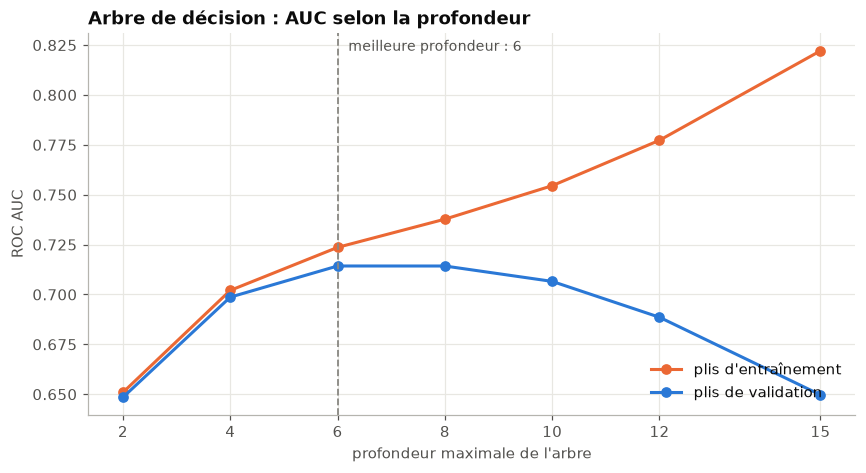

,auc_entrainement,auc_validation
profondeur,,
2,0.651,0.648
4,0.702,0.699
6,0.724,0.714
8,0.738,0.714
10,0.755,0.707
12,0.777,0.689
15,0.822,0.650


In [5]:
profondeurs = [2, 4, 6, 8, 10, 12, 15]
courbe = []
for profondeur in profondeurs:
    scores = cross_validate(make_pipeline(preparation_arbres(), DecisionTreeClassifier(max_depth=profondeur, random_state=42)),
                            X, y, cv=PLIS, scoring="roc_auc", return_train_score=True, n_jobs=5)
    courbe.append({"profondeur": profondeur, "auc_entrainement": scores["train_score"].mean(),
                   "auc_validation": scores["test_score"].mean()})
courbe = pd.DataFrame(courbe).set_index("profondeur")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(courbe.index, courbe["auc_entrainement"], color=ORANGE, marker="o", markersize=6, label="plis d'entraînement")
ax.plot(courbe.index, courbe["auc_validation"], color=BLEU, marker="o", markersize=6, label="plis de validation")
meilleure = courbe["auc_validation"].idxmax()
ax.axvline(meilleure, color=GRIS, linestyle="--", linewidth=1.2)
ax.text(meilleure + 0.2, courbe["auc_entrainement"].max(), f"meilleure profondeur : {meilleure}", color="#52514e", fontsize=9)
ax.set_xticks(profondeurs)
ax.set_xlabel("profondeur maximale de l'arbre")
ax.set_ylabel("ROC AUC")
ax.set_title("Arbre de décision : AUC selon la profondeur", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()
courbe.style.format("{:.3f}")

- **Profondeur 2 à 4 : sous-apprentissage.** L'AUC est la même sur l'entraînement et la validation, mais faible (0,65 à 0,70) : l'arbre est trop simple.
- **Profondeur 6 à 8 : le meilleur compromis**, avec 0,714 en validation.
- **Au-delà : sur-apprentissage.** L'AUC d'entraînement monte jusqu'à 0,822 à la profondeur 15, alors que celle de validation retombe à 0,650 :
  avec jusqu'à 2¹⁵ = 32 768 feuilles, l'arbre apprend par cœur de petits groupes de clients d'entraînement, et cela ne se généralise pas.
- Même à sa meilleure profondeur, un arbre seul fait à peine mieux que la moyenne des scores externes (0,716) et moins bien que la régression logistique (0,747).

In [6]:
PROFONDEUR_ARBRE = int(courbe["auc_validation"].idxmax())
oof_arbre = predire_oof(make_pipeline(preparation_arbres(),
                                      DecisionTreeClassifier(max_depth=PROFONDEUR_ARBRE, random_state=42)))
evaluer(f"Arbre de décision (profondeur {PROFONDEUR_ARBRE})", oof_arbre, len(variables))

Arbre de décision (profondeur 6) : ROC AUC 0.714 ± 0.003, PR AUC 0.186


## 4. Random Forest : le bagging

Un arbre profond apprend par cœur (variance élevée). La Random Forest en entraîne **beaucoup**, chacun différent, et fait la **moyenne** de leurs probabilités :
- chaque arbre voit un **échantillon aléatoire de clients** (ici 30 %, tirés avec remise : c'est le *bootstrap*, d'où « bagging » = *bootstrap aggregating*) ;
- à chaque coupure, il ne choisit que parmi un **sous-ensemble aléatoire de variables** (√82 ≈ 9), ce qui rend les arbres moins corrélés entre eux ;
- les erreurs individuelles se compensent dans la moyenne.

Réglages : 200 arbres, au moins 50 clients par feuille (les arbres sont profonds mais pas extrêmes), 30 % des clients par arbre
pour garder un temps de calcul raisonnable (environ 25 secondes par pli sur 8 cœurs).

In [7]:
debut = time.perf_counter()
random_forest = make_pipeline(preparation_arbres(), RandomForestClassifier(
    n_estimators=200, min_samples_leaf=50, max_features="sqrt", max_samples=0.3, n_jobs=8, random_state=42))
oof_rf = cross_val_predict(random_forest, X, y, cv=PLIS, method="predict_proba")[:, 1]
print(f"Durée : {time.perf_counter() - debut:.0f} s")
evaluer("Random Forest (200 arbres)", oof_rf, len(variables))

Durée : 176 s


Random Forest (200 arbres) : ROC AUC 0.743 ± 0.002, PR AUC 0.223


- **La moyenne de 200 arbres fait bien mieux qu'un seul arbre** : 0,743 contre 0,714. Les erreurs des arbres se compensent, ce qui réduit la variance.
- **Mais la Random Forest reste un peu sous la régression logistique** (0,747). Ici, l'essentiel du signal est monotone (plus le score externe est bas,
  plus le risque est élevé) et la logistique le capte déjà bien. Le bagging réduit la variance, mais ne corrige pas les erreurs systématiques que tous les arbres partagent.
- Les réglages sont volontairement limités (30 % des clients par arbre) pour garder un temps de calcul raisonnable : environ 3 minutes pour les 5 plis.

## 5. XGBoost : le boosting

Le boosting construit les arbres **l'un après l'autre** : chaque nouvel arbre, peu profond, corrige les erreurs de la somme
des précédents. Plus précisément, il est ajusté sur le **gradient de la log-loss**, d'où le nom *gradient boosting*.
- le **taux d'apprentissage** (`learning_rate`) réduit la contribution de chaque arbre : plus il est petit, plus il faut d'arbres, mais le modèle est plus fin ;
- trop d'arbres finit par sur-apprendre. **Early stopping** : on met de côté 10 % des clients d'entraînement de chaque pli,
  et on arrête d'ajouter des arbres quand l'AUC sur ces clients ne progresse plus depuis 100 arbres ;
- autres réglages contre le sur-apprentissage : 80 % des clients (`subsample`) et 60 % des variables (`colsample_bytree`) tirés
  pour chaque arbre, au moins 10 « clients équivalents » par feuille (`min_child_weight`), pénalité L2 sur les feuilles (`reg_lambda`).

La validation croisée est écrite à la main, pour gérer l'early stopping à l'intérieur de chaque pli :

In [8]:
def xgboost(profondeur, taux_apprentissage, nb_arbres=5000, early_stopping=True):
    return xgb.XGBClassifier(
        n_estimators=nb_arbres, learning_rate=taux_apprentissage, max_depth=profondeur,
        subsample=0.8, colsample_bytree=0.6, min_child_weight=10, reg_lambda=1.0,
        tree_method="hist", eval_metric="auc", early_stopping_rounds=100 if early_stopping else None,
        n_jobs=8, random_state=42)


def xgboost_oof(profondeur, taux_apprentissage):
    """Validation croisée avec early stopping dans chaque pli. Renvoie les prédictions et le nombre d'arbres retenus."""
    oof, nb_arbres = np.zeros(len(y)), []
    for entrainement, validation in PLIS.split(X, y):
        preparation = preparation_arbres().fit(X.iloc[entrainement])
        X_entrainement = preparation.transform(X.iloc[entrainement])
        # 10 % des clients d'entraînement du pli servent à décider quand arrêter
        X_fit, X_arret, y_fit, y_arret = train_test_split(X_entrainement, y[entrainement], test_size=0.1,
                                                          stratify=y[entrainement], random_state=42)
        modele = xgboost(profondeur, taux_apprentissage).fit(X_fit, y_fit, eval_set=[(X_arret, y_arret)], verbose=False)
        oof[validation] = modele.predict_proba(preparation.transform(X.iloc[validation]))[:, 1]  # avec le meilleur nombre d'arbres
        nb_arbres.append(modele.best_iteration + 1)
    return oof, nb_arbres

### 5.1 Choix de la profondeur des arbres

Comparaison rapide avec un taux d'apprentissage de 0,1 :

In [9]:
choix_profondeur = []
for profondeur in [3, 5, 7]:
    debut = time.perf_counter()
    oof, nb_arbres = xgboost_oof(profondeur, 0.1)
    roc = [roc_auc_score(y[i], oof[i]) for i in INDICES_PLIS]
    choix_profondeur.append({"profondeur": profondeur, "roc_auc": np.mean(roc), "ecart_type": np.std(roc),
                             "nb_arbres_moyen": np.mean(nb_arbres), "duree_s": time.perf_counter() - debut})
choix_profondeur = pd.DataFrame(choix_profondeur).set_index("profondeur")
choix_profondeur.style.format({"roc_auc": "{:.4f}", "ecart_type": "{:.4f}", "nb_arbres_moyen": "{:.0f}", "duree_s": "{:.0f}"})

,roc_auc,ecart_type,nb_arbres_moyen,duree_s
profondeur,,,,
3,0.7565,0.0021,362,589
5,0.7546,0.0018,169,360
7,0.7522,0.0029,92,282


- **Les arbres peu profonds gagnent** : 0,7565 en profondeur 3 contre 0,7522 en profondeur 7. Un arbre de profondeur 3 combine au plus 3 variables,
  ce qui suffit ici ; les arbres profonds sur-apprennent plus vite (l'early stopping les arrête après 92 arbres en moyenne, contre 362).
- On garde la profondeur 3 et on relance avec un taux d'apprentissage plus petit (0,05), donc plus d'arbres, plus finement ajustés.

In [10]:
PROFONDEUR_XGB = int(choix_profondeur["roc_auc"].idxmax())
debut = time.perf_counter()
oof_xgb, nb_arbres_xgb = xgboost_oof(PROFONDEUR_XGB, 0.05)
print(f"Durée : {time.perf_counter() - debut:.0f} s ; arbres retenus par pli : {nb_arbres_xgb}")
evaluer(f"XGBoost (profondeur {PROFONDEUR_XGB}, taux 0,05)", oof_xgb, len(variables))

Durée : 555 s ; arbres retenus par pli : [823, 1088, 344, 909, 844]
XGBoost (profondeur 3, taux 0,05) : ROC AUC 0.756 ± 0.002, PR AUC 0.240


### 5.2 Les variables les plus utilisées

On entraîne XGBoost sur tout le jeu d'apprentissage, avec le nombre moyen d'arbres trouvé par l'early stopping.
L'importance « gain » de XGBoost est la baisse **moyenne** de la log-loss obtenue à chaque coupure sur une variable.
Le mot « total » du graphique et du message ci-dessous désigne la somme de ces gains moyens, pas un gain cumulé
(le gain cumulé sur toutes les coupures, `total_gain`, est utilisé au notebook 04).

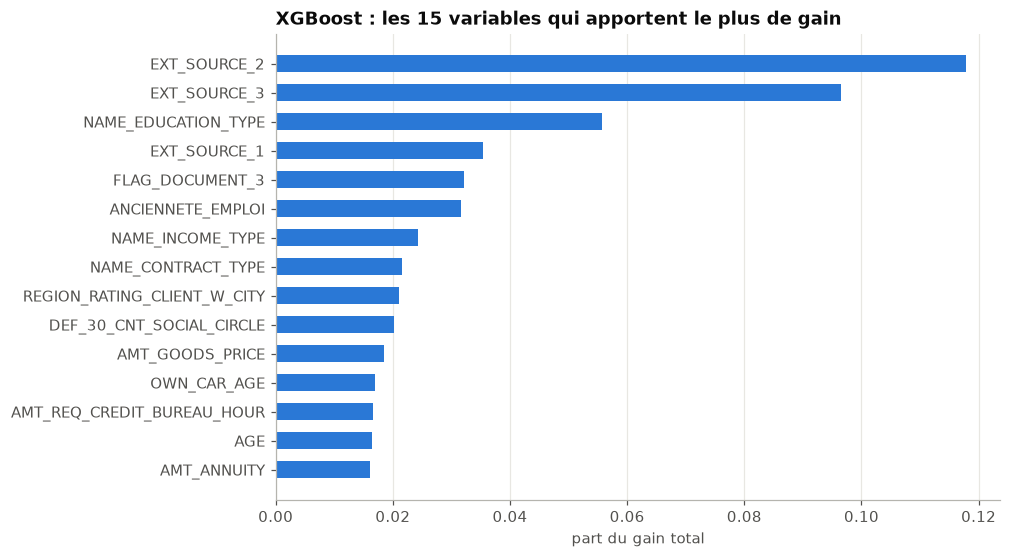

Les 15 premières variables représentent 54% du gain total


In [11]:
preparation_finale = preparation_arbres().fit(X)
xgb_complet = xgboost(PROFONDEUR_XGB, 0.05, nb_arbres=int(np.mean(nb_arbres_xgb)), early_stopping=False)
xgb_complet.fit(preparation_finale.transform(X), y)

gain = pd.Series(xgb_complet.get_booster().get_score(importance_type="gain"))
gain.index = [(numeriques + categorielles)[int(f[1:])] if f.startswith("f") and f[1:].isdigit() else f for f in gain.index]
gain = (gain / gain.sum()).sort_values()
plus_importantes = gain.tail(15)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(plus_importantes.index, plus_importantes, color=BLEU, height=0.6)
ax.set_xlabel("part du gain total")
ax.set_title("XGBoost : les 15 variables qui apportent le plus de gain", loc="left")
ax.grid(axis="y", visible=False)
plt.show()
print(f"Les 15 premières variables représentent {plus_importantes.sum():.0%} du gain total")

- **Les scores externes dominent encore** : `EXT_SOURCE_2` et `EXT_SOURCE_3` pèsent à eux deux 22 % de l'importance, suivis du niveau d'études et d'`EXT_SOURCE_1`.
- **Deux variables qu'on n'attendait pas** :
  - `FLAG_DOCUMENT_3` (5ᵉ) : les 71 % de clients qui ont fourni le document n° 3 font défaut à 8,8 %, contre 6,2 % pour les autres ;
  - `DEF_30_CNT_SOCIAL_CIRCLE` : le nombre de personnes de l'entourage du client ayant eu un retard de paiement (7,8 % de défauts sans aucune, 11,8 % avec deux ou plus).
- **Le signal est dispersé** : les 15 premières variables ne représentent que 54 % de l'importance totale.
- **Limites de cette importance** : elle ne dit ni dans quel sens une variable joue, ni pourquoi un client donné est jugé risqué.
  Et comme c'est un gain moyen par coupure, une variable utilisée dans très peu de coupures peut paraître importante.
  Le gain cumulé (notebook 04) et les valeurs SHAP (étape 10) répondront à ces limites.

## 6. Comparaison des modèles

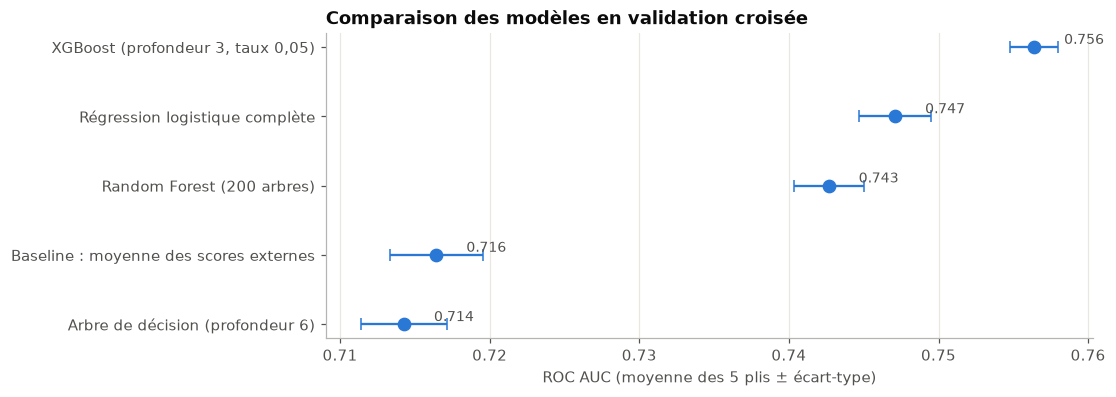

,variables,roc_auc,ecart_type,pr_auc
modele,,,,
"XGBoost (profondeur 3, taux 0,05)",82,0.756,0.002,0.240
Régression logistique complète,82,0.747,0.002,0.227
Random Forest (200 arbres),82,0.743,0.002,0.223
Baseline : moyenne des scores externes,3,0.716,0.003,0.189
Arbre de décision (profondeur 6),82,0.714,0.003,0.186


In [12]:
comparaison = pd.DataFrame(resultats).set_index("modele").sort_values("roc_auc")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.errorbar(comparaison["roc_auc"], comparaison.index, xerr=comparaison["ecart_type"], fmt="o", color=BLEU,
            markersize=8, capsize=4, elinewidth=1.5)
for nom, ligne in comparaison.iterrows():
    ax.text(ligne["roc_auc"] + 0.002, nom, f"{ligne['roc_auc']:.3f}", va="bottom", color="#52514e", fontsize=9)
ax.xaxis.set_major_locator(MultipleLocator(0.01))
ax.set_xlabel("ROC AUC (moyenne des 5 plis ± écart-type)")
ax.set_title("Comparaison des modèles en validation croisée", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

(comparaison.drop(columns="auc_par_pli").sort_values("roc_auc", ascending=False)
 .style.format({"variables": "{:,.0f}", "roc_auc": "{:.3f}", "ecart_type": "{:.3f}", "pr_auc": "{:.3f}"}))

L'écart entre les modèles est petit. Est-il réel ou dû au hasard du découpage ?
Comme tous les modèles sont évalués **sur les mêmes plis**, on peut comparer pli par pli :

In [13]:
par_pli = pd.DataFrame({r["modele"]: r["auc_par_pli"] for r in resultats}, index=[f"pli {k}" for k in range(1, 6)])
nom_xgb = [m for m in par_pli.columns if m.startswith("XGBoost")][0]
par_pli["gain XGBoost - logistique"] = par_pli[nom_xgb] - par_pli["Régression logistique complète"]
par_pli[["Régression logistique complète", nom_xgb, "gain XGBoost - logistique"]].style.format("{:+.4f}", subset=["gain XGBoost - logistique"]).format("{:.4f}", subset=["Régression logistique complète", nom_xgb])

,Régression logistique complète,"XGBoost (profondeur 3, taux 0,05)",gain XGBoost - logistique
pli 1,0.7454,0.7548,+0.0093
pli 2,0.7448,0.7566,+0.0118
pli 3,0.7516,0.7563,+0.0047
pli 4,0.7470,0.7593,+0.0123
pli 5,0.7467,0.7550,+0.0084


- **XGBoost bat la régression logistique sur les 5 plis**, de +0,005 à +0,012 (+0,009 en moyenne).
- Si l'écart venait du hasard du découpage, XGBoost perdrait sur certains plis. Le gain est petit, mais **systématique**.

In [14]:
# Prédictions out-of-fold gardées pour la suite (seuil, comparaison finale)
pd.DataFrame({
    "SK_ID_CURR": train["SK_ID_CURR"].to_numpy(),
    "TARGET": y,
    "arbre": oof_arbre,
    "random_forest": oof_rf,
    "xgboost": oof_xgb,
}).to_parquet(DOSSIER_PROCESSED / "oof_03.parquet", index=False)
print("Enregistré : data/processed/oof_03.parquet")

Enregistré : data/processed/oof_03.parquet


**À retenir** :

| Modèle | ROC AUC | PR AUC | Ce qu'il montre |
|---|---|---|---|
| Arbre de décision (profondeur 6) | 0,714 | 0,186 | lisible, mais instable et grossier (peu de niveaux de risque) |
| Random Forest | 0,743 | 0,223 | le **bagging** réduit la variance (+0,03 sur un arbre seul) |
| Régression logistique | 0,747 | 0,227 | déjà forte, car le signal est surtout monotone |
| **XGBoost (profondeur 3)** | **0,756** | **0,240** | le **boosting** corrige les erreurs pas à pas : le meilleur modèle |

- La **profondeur** règle le passage du sous-apprentissage au sur-apprentissage, et l'**early stopping** évite d'empiler trop d'arbres
  (le nombre d'arbres retenu varie d'un pli à l'autre : de 344 à 1 088).
- Le gain de XGBoost sur la logistique est modeste mais présent sur tous les plis. Il a un prix : environ 10 minutes de validation croisée
  par réglage (contre 30 secondes pour la logistique), et un modèle moins lisible, d'où SHAP plus tard.

**Prochaine étape** (étape 7 du README) : ajouter les 17 nouvelles variables (ratios et historique de crédit de `bureau.csv`)
à la régression logistique et à XGBoost, et mesurer ce qu'elles apportent. Le jeu de test n'a toujours pas été utilisé.